In [1]:
!mamba install pandas


mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.610 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [5]:
# 1. Ścieżki do plików
folder = Path(".")
files = [
    folder / "Sonda1.txt",
    folder / "Sonda2.txt",
]

In [6]:
data = pd.concat(
    [
        pd.read_csv(file, sep="\t", decimal=",")
        for file in files
    ],
    ignore_index=True,
)

In [7]:
data = data.sort_values(["z", "y"]).reset_index(drop=True)


data["z"] = data["z"] + deltaz

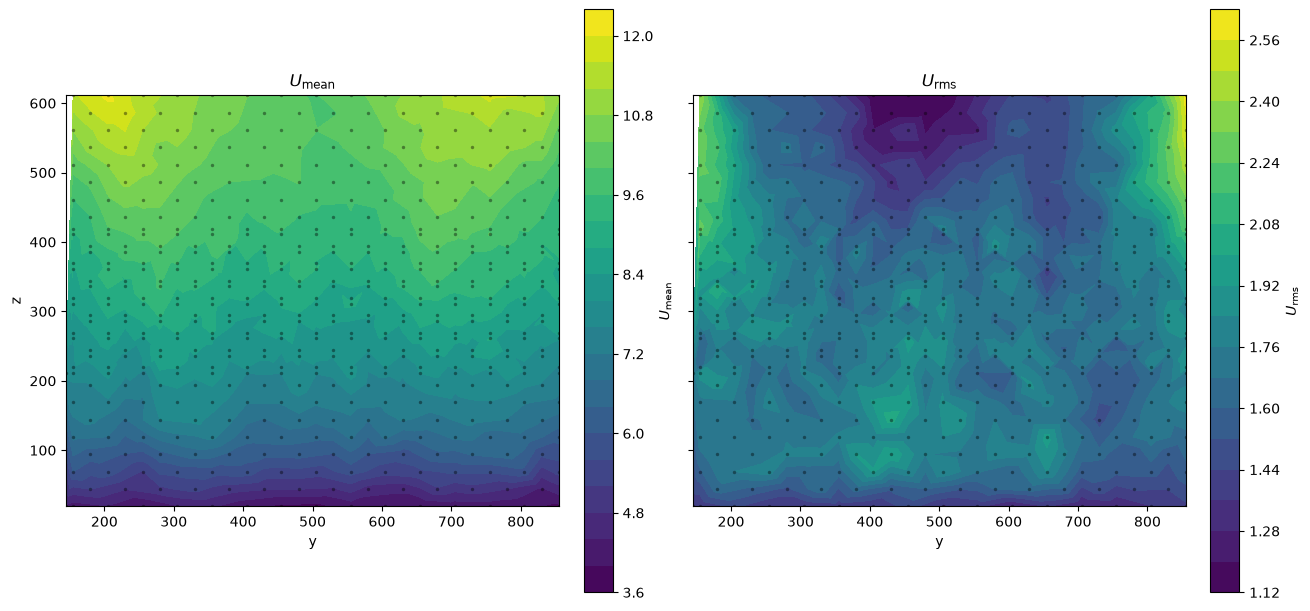

In [8]:
plot_data = data.copy()
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

fields = [
    ("Umean", r"$U_{\mathrm{mean}}$"),
    ("Urms", r"$U_{\mathrm{rms}}$"),
]

for ax, (column, title) in zip(axes, fields):

    # Wybór punktów z poprawnymi współrzędnymi i wartością pola
    valid = np.isfinite(
        plot_data[["y", "z", column]].to_numpy(dtype=float)
    ).all(axis=1)

    points = plot_data.loc[valid]

    y = points["y"].to_numpy()
    z = points["z"].to_numpy()
    values = points[column].to_numpy()

    # Wypełniona mapa konturowa
    contour = ax.tricontourf(
        y,
        z,
        values,
        levels=20,
        cmap="viridis",
    )

    # Punkty pomiarowe — usuń ten fragment, jeśli nie chcesz ich wyświetlać
    ax.scatter(
        y,
        z,
        s=6,
        color="black",
        alpha=0.4,
        linewidths=0,
    )

    ax.set_title(title)
    ax.set_xlabel("y")
    ax.set_aspect("equal", adjustable="box")

    colorbar = fig.colorbar(contour, ax=ax)
    colorbar.set_label(title)

axes[0].set_ylabel("z")

plt.show()

In [9]:
Umean = (
    data.pivot(index="z", columns="y", values="Umean")
    .sort_index(axis=0)
    .sort_index(axis=1)
)

Urms = (
    data.pivot(index="z", columns="y", values="Urms")
    .sort_index(axis=0)
    .sort_index(axis=1)
)

print("Połączone dane:")
print(data.head())

print("\nTabela Umean:")
print(Umean.iloc[:5, :5])

print("\nTabela Urms:")
print(Urms.iloc[:5, :5])

Połączone dane:
     y     z     Umean      Urms
0  145  19.2  4.317579  1.366226
1  155  19.2  4.173745  1.368749
2  205  19.2  4.377675  1.457573
3  255  19.2  3.949804  1.362172
4  305  19.2  4.367922  1.363271

Tabela Umean:
y           145       155       180       205       230
z                                                      
19.2   4.317579  4.173745       NaN  4.377675       NaN
44.2        NaN       NaN  5.218267       NaN  4.823994
69.2        NaN  6.003111       NaN  5.819183       NaN
94.2        NaN       NaN  6.192314       NaN  5.978980
119.2       NaN  6.887345       NaN  6.794033       NaN

Tabela Urms:
y           145       155       180       205       230
z                                                      
19.2   1.366226  1.368749       NaN  1.457573       NaN
44.2        NaN       NaN  1.645537       NaN  1.579843
69.2        NaN  1.583023       NaN  1.759978       NaN
94.2        NaN       NaN  1.757432       NaN  1.711650
119.2       NaN  1.736092    

In [10]:
Umean_avg = (
    Umean.mean(axis=1, skipna=True)
    .to_frame(name="Umean")
    .reset_index()
)

Urms_avg = (
    Urms.mean(axis=1, skipna=True)
    .to_frame(name="Urms")
    .reset_index()
)

print("Umean uśrednione po y:")
print(Umean_avg.head())

print("\nUrms uśrednione po y:")
print(Urms_avg.head())

Umean uśrednione po y:
       z     Umean
0   19.2  4.126094
1   44.2  4.881865
2   69.2  5.628025
3   94.2  6.169831
4  119.2  6.728174

Urms uśrednione po y:
       z      Urms
0   19.2  1.364247
1   44.2  1.564876
2   69.2  1.691611
3   94.2  1.749878
4  119.2  1.746358


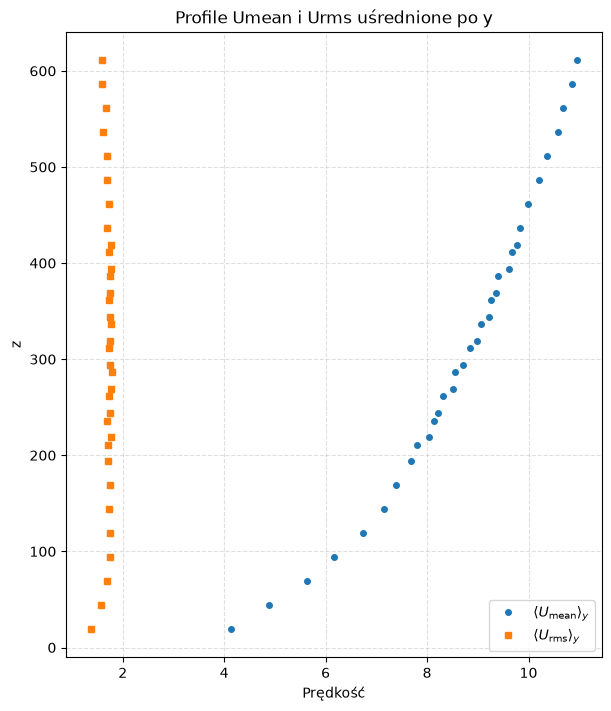

In [14]:
profile_mean = Umean_avg.sort_values("z")
profile_rms = Urms_avg.sort_values("z")

fig, ax = plt.subplots(figsize=(6, 7), constrained_layout=True)

# Profil Umean
ax.plot(
    profile_mean["Umean"],
    profile_mean["z"],
    marker="o",
    markersize=4,
    linestyle=" ",
    linewidth=1.5,
    color="tab:blue",
    label=r"$\langle U_{\mathrm{mean}} \rangle_y$",
)

# Profil Urms
ax.plot(
    profile_rms["Urms"],
    profile_rms["z"],
    marker="s",
    markersize=4,
    linestyle=" ",
    linewidth=1.5,
    color="tab:orange",
    label=r"$\langle U_{\mathrm{rms}} \rangle_y$",
)

ax.set_xlabel("Prędkość")  # Dopisz jednostkę, np. "Prędkość [m/s]"
ax.set_ylabel("z")         # Dopisz jednostkę, np. "z [mm]"
ax.set_title("Profile Umean i Urms uśrednione po y")

ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

fig.savefig("profile_Umean_Urms.png", dpi=300, bbox_inches="tight")
plt.show()

A = 7.786166
B = 0.301436
RMSE = 0.077456
Model: Umean = 7.786166 * (z / 200) ** 0.301436


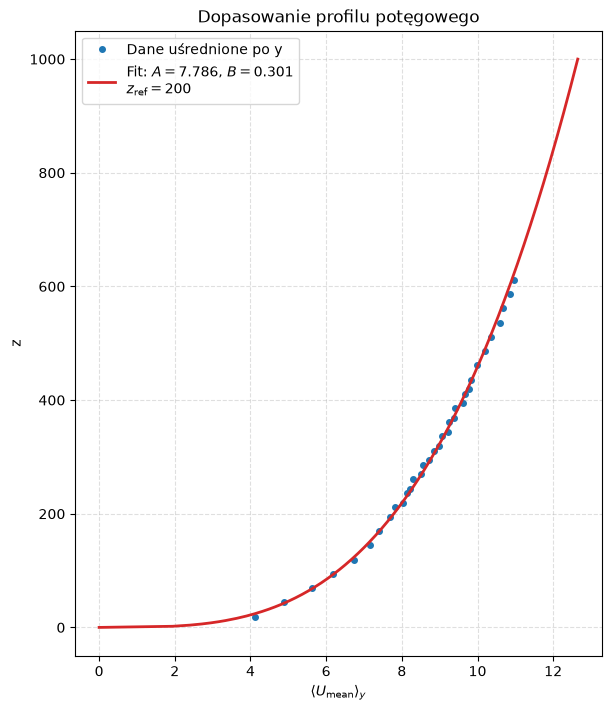

In [12]:
profile = (
    Umean_avg[["z", "Umean"]]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_values("z")
)

# Dopasowanie tylko dla z > 0
profile = profile.loc[profile["z"] > 0].copy()

z = profile["z"].to_numpy(dtype=float)
u = profile["Umean"].to_numpy(dtype=float)

if len(z) < 3 or np.unique(z).size < 3:
    raise ValueError("Potrzebne są co najmniej 3 różne wartości z > 0.")

# 2. Przybliżenia początkowe parametrów
A0 = float(u[np.argmin(np.abs(z - zref))])
B0 = 0.2

# 3. Dopasowanie A i B — bez narzucania ograniczeń
parameters, covariance = curve_fit(
    power_law,
    z,
    u,
    p0=[A0, B0],
    maxfev=10000,
)

A, B = parameters

# 4. Ocena dopasowania
u_predicted = power_law(z, A, B)
rmse = np.sqrt(np.mean((u - u_predicted) ** 2))

print(f"A = {A:.6f}")
print(f"B = {B:.6f}")
print(f"RMSE = {rmse:.6f}")
print(f"Model: Umean = {A:.6f} * (z / {zref:g}) ** {B:.6f}")

# 5. Gładka krzywa w zakresie dopasowania
z_fit = np.linspace(0, 1000, 500)
u_fit = power_law(z_fit, A, B)

# 6. Wykres
fig, ax = plt.subplots(figsize=(6, 7), constrained_layout=True)

ax.plot(
    u,
    z,
    "o",
    markersize=4,
    color="tab:blue",
    label="Dane uśrednione po y",
)

ax.plot(
    u_fit,
    z_fit,
    "-",
    linewidth=2,
    color="tab:red",
    label=(
        rf"Fit: $A={A:.3f}$, $B={B:.3f}$"
        "\n"
        rf"$z_{{\mathrm{{ref}}}}={zref:g}$"
    ),
)

ax.set_xlabel(r"$\langle U_{\mathrm{mean}} \rangle_y$")
ax.set_ylabel("z")
ax.set_title("Dopasowanie profilu potęgowego")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

fig.savefig("fit_Umean.png", dpi=300, bbox_inches="tight")
plt.show()

Regresja 1:
log10(z) = 0.181101 * Umean_fit + (0.806527)

Regresja 2:
Umean_fit = 5.264882 * log10(z) + (-3.793854)


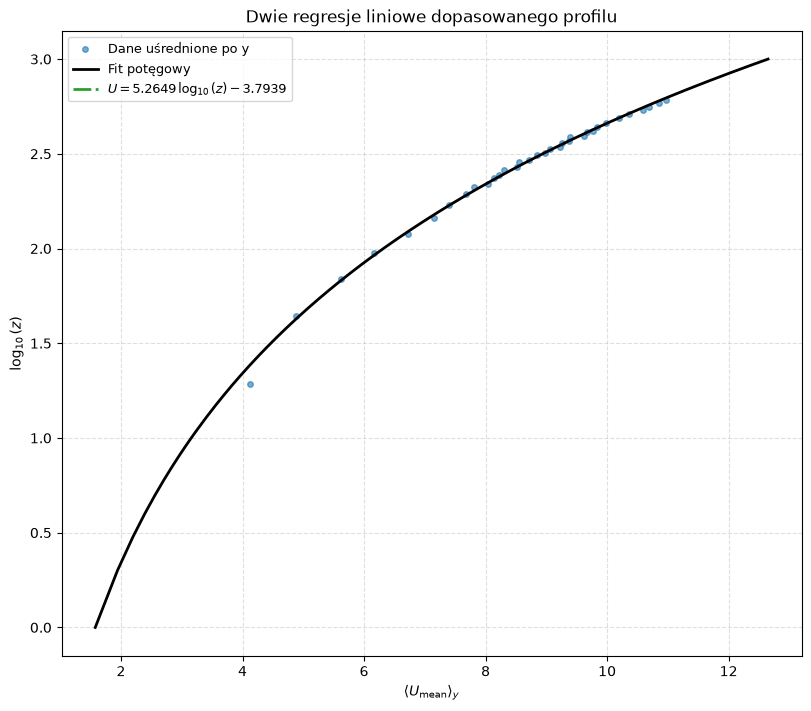

In [27]:
z_fit = np.linspace(1, 1000, 1000)

Umean_fit = power_law(z_fit, A, B)
log_z = np.log10(z_fit)

# 2. Pierwsza regresja: log10(z) = a1 * Umean_fit + b1
a1, b1 = np.polyfit(Umean_fit, log_z, deg=1)

# 3. Druga regresja: Umean_fit = a2 * log10(z) + b2
a2, b2 = np.polyfit(log_z, Umean_fit, deg=1)

print("Regresja 1:")
print(f"log10(z) = {a1:.6f} * Umean_fit + ({b1:.6f})")

print("\nRegresja 2:")
print(f"Umean_fit = {a2:.6f} * log10(z) + ({b2:.6f})")

# 4. Punkty obu prostych do wyświetlenia
u_line = np.linspace(Umean_fit.min(), Umean_fit.max(), 1000)

# Regresja 1: współrzędne (Umean, log10(z))
log_z_line_1 = a1 * u_line + b1

# Regresja 2: również rysujemy (Umean, log10(z)),
# ale tym razem Umean jest obliczane z log10(z).
log_z_line_2 = np.linspace(log_z.max(), log_z.max(), 1000)
u_line_2 = a2 * log_z_line_2 + b2

# 5. Wykres
fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)

# Oryginalne dane użyte do dopasowania potęgowego
ax.plot(
    u,
    np.log10(z),
    "o",
    markersize=4,
    color="tab:blue",
    alpha=0.6,
    label="Dane uśrednione po y",
)

# Dopasowana funkcja potęgowa
ax.plot(
    Umean_fit,
    log_z,
    color="black",
    linewidth=2,
    label="Fit potęgowy",
)

# Pierwsza prosta
#ax.plot(
#    u_line,
#    log_z_line_1,
#    "--",
#    color="tab:red",
#    linewidth=2,
#    label=(
#        rf"$\log_{{10}}(z) = {a1:.4f}\,U"
#        rf"{b1:+.4f}$"
#    ),
#)

# Druga prosta
ax.plot(
    u_line_2,
    log_z_line_2,
    "-.",
    color="tab:green",
    linewidth=2,
    label=(
        rf"$U = {a2:.4f}\,\log_{{10}}(z)"
        rf"{b2:+.4f}$"
    ),
)

ax.set_xlabel(r"$\langle U_{\mathrm{mean}} \rangle_y$")
ax.set_ylabel(r"$\log_{10}(z)$")
ax.set_title("Dwie regresje liniowe dopasowanego profilu")

# Oś pozostaje liniowa — log10 jest już obliczony w danych.
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(fontsize=9)

fig.savefig(
    "fit_Umean_dwie_regresje.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [26]:
ustar = 0.4/a1
z0 = np.exp(b1)

ustar2 = a2*0.4
z02 = np.exp(-b2/a2)

print(ustar, z0)
print(ustar2, z02)


2.208711310621683 2.2401142580266478
2.10595275172861 2.0556585485384558
